# 1 · Linear regression

```{math}
\hat y = w x + b
```

**Family:** linear models · **Task:** regression

In the video, a yellow line starts almost flat with long red residual bars, then
swings into place along the blue points. That motion is gradient descent on the
mean squared error:

```{math}
\mathrm{MSE}(w,b) = \frac1n\sum_{i=1}^n (w x_i + b - y_i)^2,\qquad
\frac{\partial\,\mathrm{MSE}}{\partial w} = \frac2n\sum_i (\hat y_i - y_i)\,x_i,\qquad
\frac{\partial\,\mathrm{MSE}}{\partial b} = \frac2n\sum_i (\hat y_i - y_i)
```

Each step moves $(w, b)$ a little way against the gradient: $w \leftarrow w - \alpha\,\partial_w$,
$b \leftarrow b - \alpha\,\partial_b$.

## Imports

`ml8` is the book's own package; [The sample data](00_sample_data.ipynb) explains how it is
imported. This chapter uses:

| File | What this chapter uses |
|---|---|
| `ml8/data.py` | `data.regression_data`: the 1-D regression sample |
| `ml8/scratch.py` | `scratch.linear_gd`: gradient descent for $\hat y = wx + b$ |
| `ml8/models.py` | `models.LINEAR_RECORD`: the gradient-descent steps to record |
| `ml8/plotting.py` | the palette (`P.BLUE`, `P.RED`, `P.YELLOW`) |

In [1]:
# ml8 sits one folder above notebooks/, so put that folder on Python's search path
import sys
sys.path.insert(0, "..")

# Installed packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# The book's own modules
from ml8 import data              # ml8/data.py: the seeded sample datasets
from ml8 import models            # ml8/models.py: shared model settings
from ml8 import plotting as P     # ml8/plotting.py: colours and plot helpers
from ml8 import scratch           # ml8/scratch.py: the from-scratch formulas

P.use_style()  # the dark style used by every figure
pd.set_option("display.precision", 4)

In [2]:
reg = data.regression_data()
x, y = reg.x.to_numpy(), reg.y.to_numpy()
(w, b), hist = scratch.linear_gd(x, y, record=set(models.LINEAR_RECORD))
gd = pd.DataFrame(hist, columns=["iter", "w", "b", "mse"])
gd

,iter,w,b,mse
0,0,-0.2000,5.0000,95.6645
1,1,1.9517,5.3019,15.3269
2,2,1.2695,5.1703,7.0919
3,3,1.4929,5.1776,6.2196
4,5,1.4531,5.1185,6.0571
5,8,1.4591,5.0419,5.9587
6,12,1.4742,4.9444,5.8377
7,20,1.5023,4.7608,5.6231
8,35,1.5493,4.4540,5.3030
9,60,1.6134,4.0353,4.9440


## Does gradient descent reach the exact answer?

Least squares also has a closed form, $\hat\beta = (X^\top X)^{-1}X^\top y$. Gradient
descent, `numpy.polyfit` and scikit-learn should agree.

In [3]:
X = np.c_[np.ones_like(x), x]
beta = np.linalg.solve(X.T @ X, X.T @ y)
sk = LinearRegression().fit(x[:, None], y)
pd.DataFrame({
    "w": [w, beta[1], np.polyfit(x, y, 1)[0], sk.coef_[0]],
    "b": [b, beta[0], np.polyfit(x, y, 1)[1], sk.intercept_],
}, index=["gradient descent", "normal equations", "numpy.polyfit", "scikit-learn"])

,w,b
gradient descent,1.8372,2.573
normal equations,1.8372,2.573
numpy.polyfit,1.8372,2.573
scikit-learn,1.8372,2.573


In [4]:
print(f"R² = {sk.score(x[:, None], y):.3f}  (true line: w = 1.8, b = 3)")

R² = 0.864  (true line: w = 1.8, b = 3)


## The video's animation, frame by frame

Red bars are residuals $y_i - \hat y_i$; their squared lengths are what the loss adds up.

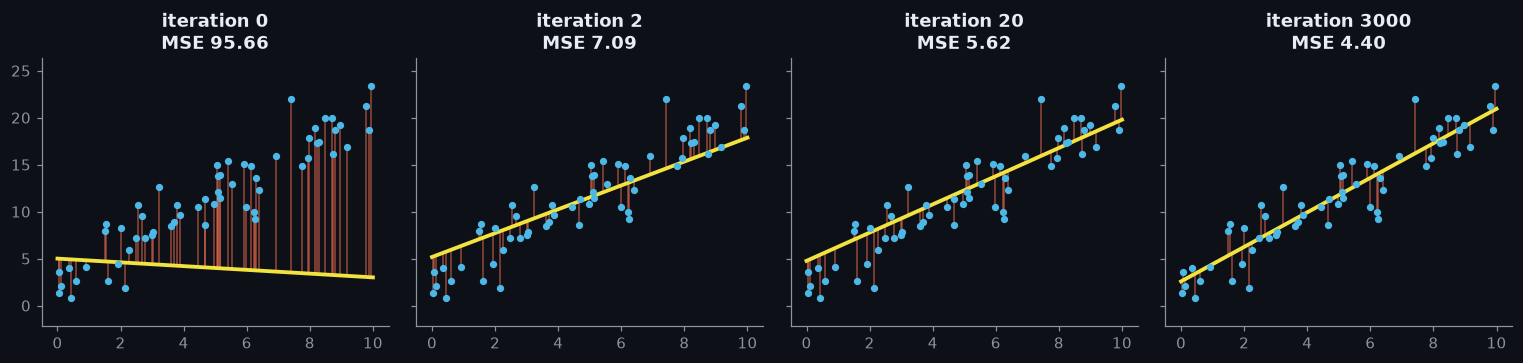

In [5]:
frames = [0, 2, 20, 3000]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, it in zip(axes, frames):
    r = gd[gd.iter == it].iloc[0]
    yhat = r.w * x + r.b
    ax.vlines(x, y, yhat, colors=P.RED, alpha=0.6, lw=1)
    ax.scatter(x, y, s=14, c=P.BLUE, zorder=3)
    ax.plot([0, 10], [r.b, r.w * 10 + r.b], c=P.YELLOW, lw=2.5)
    ax.set_title(f"iteration {it}\nMSE {r.mse:.2f}")
    ax.set_ylim(y.min() - 3, y.max() + 3)
plt.tight_layout()

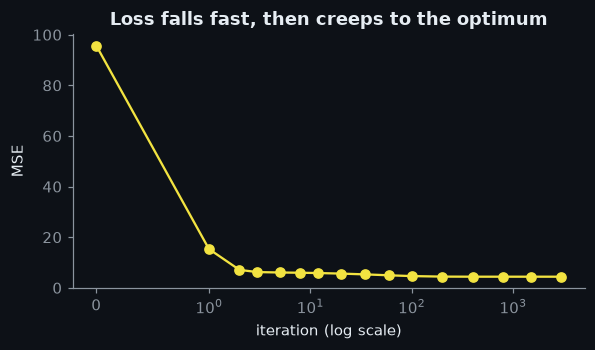

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(gd.iter, gd.mse, marker="o", c=P.YELLOW)
ax.set_xscale("symlog", linthresh=1); ax.set_xlabel("iteration (log scale)"); ax.set_ylabel("MSE")
ax.set_title("Loss falls fast, then creeps to the optimum");

## Takeaways

- The first steps fix the slope; the intercept converges far more slowly because $x$ is
  not centred. Standardising $x$ would make both converge at the same rate.
- The minimum MSE is not zero: the remaining error is the noise built into the data.

**Try it:** change `lr` in `scratch.linear_gd` to `0.05`. With unscaled $x$ in $[0, 10]$
the updates overshoot and diverge, which is why learning rates and feature scaling matter.